# 04 · Densidad de cotización

Estimación, calibración y validación de `pension_mc.contributions`. El modelo es una cadena de Markov mensual (cotiza / no cotiza) con una propensión individual a cotizar:

$$\pi_i(a) = \text{logística}\big(c_k(a) + \beta\,\eta_i(a)\big), \qquad P(\text{salir}) = \mu(a)\,(1-\pi_i), \qquad \mu(a) = \mu_0\, e^{-\kappa (a - 40)/10}$$

- $\pi_k(a)$: proporción de la población del tipo $k$ (educación × sexo) que cotiza a la edad $a$ (GEIH 2023–2025); $c_k(a)$ hace que el promedio sobre $\eta$ la reproduzca.
- $\eta_i(a)$: propensión individual, $N(0,1)$. Sigue un AR(1) con persistencia anual $\rho_\eta$ hasta los 30 años y queda fija después: la situación laboral se consolida con la edad. La edad de consolidación se estima (sección 7).
- $\beta$: heterogeneidad (con β grande, unos cotizan casi siempre y otros casi nunca); $\mu_0, \kappa$: rotación de corto plazo.
- La probabilidad de entrar se fija para que la marginal de cada persona siga su $\pi_i(a)$.

La GEIH es de corte transversal: no sigue a las personas y no identifica $(\mu_0, \kappa, \beta, \rho_\eta)$ por sí sola. **Este notebook muestra por qué la calibración importa tanto como las tasas, y cómo la validación obligó a cambiar el modelo dos veces.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import optimize

from pension_mc import contributions as C
from pension_mc.wages import EDUCACION, NIVELES, SEXOS, clave
from pension_mc.config import DATA_PROCESSED as P

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "legend.frameon": False,
    "lines.linewidth": 2, "figure.figsize": (9, 4.2), "figure.dpi": 110, "font.size": 10,
})
pct = lambda d=0: mtick.PercentFormatter(1, decimals=d)
# Semanas exigidas a las cohortes jóvenes (se pensionan después de 2036)
REQ_GPM = {"Hombre": 1150, "Mujer": 1000}
REQ_RPM = {"Hombre": 1300, "Mujer": 1000}
EDAD_PEN = {"Hombre": 62, "Mujer": 57}

geih = pd.read_parquet(P / "geih_pensiones.parquet")
obs = C.tasas_observadas(geih)
tasas = C.suavizar(obs)
pob = C.poblacion_por_tipo(obs)
obj = {g: C.objetivo_periodo(geih, edades=g) for g in C.GRUPOS_PERIODO}
E = list(range(C.EDAD_INICIO, C.EDAD_FIN + 1))
tasas_l = {k: list(v) for k, v in tasas.items()}
print("Cotizantes con ≥ 3 años en el empleo actual (GEIH):", {f"{a}–{b}": f"{v:.1%}" for (a, b), v in obj.items()})

Cotizantes con ≥ 3 años en el empleo actual (GEIH): {'25–44': '46.3%', '45–64': '72.6%'}


## 1. Tasas de cotización por edad (GEIH 2023–2025)

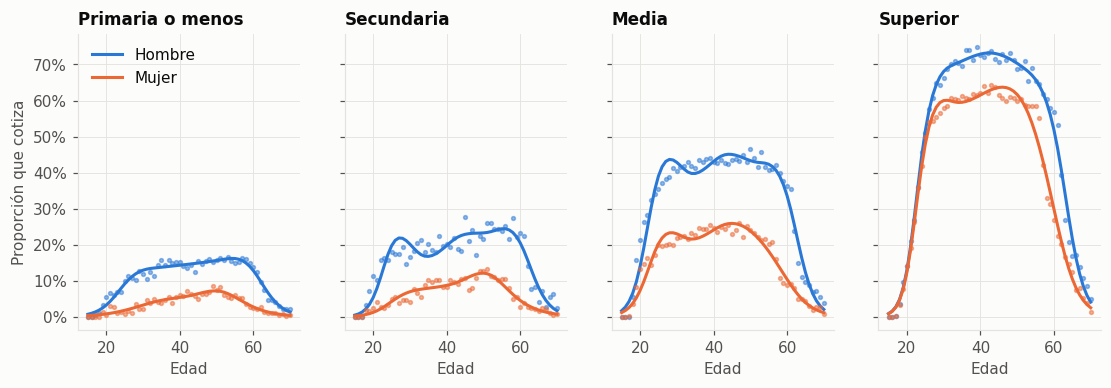

In [2]:
edades = np.arange(C.EDAD_INICIO, C.EDAD_FIN + 1)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), sharey=True)
for ax, e in zip(axes, NIVELES):
    for i, s in enumerate(SEXOS):
        o = obs[(obs.educ == e) & (obs.sexo == s)]
        ax.plot(o.edad, o.tasa, "o", ms=2.5, color=SERIES[i], alpha=0.5)
        ax.plot(edades, tasas[clave(e, s)], color=SERIES[i], label=s)
    ax.set_title(e, fontsize=11)
    ax.set_xlabel("Edad")
axes[0].yaxis.set_major_formatter(pct())
axes[0].set_ylabel("Proporción que cotiza")
axes[0].legend(loc="upper left")
plt.show()

Puntos: tasa observada por edad. Líneas: logit con spline natural (7 grados de libertad) por tipo. La brecha por educación es enorme: con educación superior cotiza hasta el ~70 % de la población; con primaria o menos, menos del 20 %.

## 2. Calibración: tres versiones del modelo

Momentos disponibles:

| Momento | Valor | Fuente |
|---|---|---|
| Cotizantes del mes / activos (cotizaron en los últimos 6 meses) | 0,82 | MinTrabajo (datos.gov.co `sk9s-yxmi`), corrigiendo columnas invertidas en las AFP |
| Cotizantes con ≥ 3 años en el empleo actual: 25–44 / 45–64 años | 0,46 / 0,73 | GEIH (P6426); cota inferior de la duración del periodo de cotización |
| Alguna vez cotizó (afiliados / población de 18 a 70 años) | 0,77 | MinTrabajo y GEIH; cota superior (el registro incluye inactivos fallecidos o fuera del país) |

Versiones:

- **A:** η permanente y rotación constante, calibrada con rotación + alguna vez.
- **B:** η permanente y rotación que cae con la edad, calibrada con rotación + duración por edad.
- **C (base):** η que se mueve hasta los 30 años, calibrada con los cuatro momentos.

In [3]:
def calibrar_A():
    def resid(p):
        mo = C.momentos(C.ModeloCotizacion(E, tasas_l, np.exp(p[0]), np.exp(p[1])), pob)
        return [mo["cotizantes_sobre_activos"] - 0.82, mo["alguna_vez"] - 0.77]
    r = optimize.least_squares(resid, x0=np.log([0.1, 1.3]), diff_step=0.05)
    return C.ModeloCotizacion(E, tasas_l, float(np.exp(r.x[0])), float(np.exp(r.x[1])))

mA = calibrar_A()
mB = C.calibrar(tasas, pob, objetivos_periodo=obj, x0=(0.2, 0.8, 4.0))
mC = C.ModeloCotizacion.cargar()                     # base, estimada con C.estimar()
modelos = {"A": mA, "B": mB, "C (base)": mC}
filas = {}
for k, m in modelos.items():
    mo = C.momentos(m, pob)
    filas[k] = {"μ₀": m.mu, "κ": m.kappa, "β": m.beta, "ρ_η": m.rho_eta, **mo}
filas["Dato"] = {"cotizantes_sobre_activos": 0.82, "alguna_vez": 0.77,
                 "periodo_25_44": obj[(25, 44)], "periodo_45_64": obj[(45, 64)]}
cols = ["μ₀", "κ", "β", "ρ_η", "tasa", "cotizantes_sobre_activos", "alguna_vez", "periodo_25_44", "periodo_45_64"]
pd.DataFrame(filas).T[cols].style.format("{:.3f}", na_rep="")

,μ₀,κ,β,ρ_η,tasa,cotizantes_sobre_activos,alguna_vez,periodo_25_44,periodo_45_64
A,0.120,0.000,1.441,1.000,0.289,0.820,0.770,0.311,0.308
B,0.194,0.828,4.091,1.000,0.288,0.820,0.614,0.463,0.726
C (base),0.300,0.580,6.190,0.700,0.289,0.821,0.769,0.463,0.730
Dato,,,,,,0.820,0.770,0.463,0.726


- **A** reproduce la rotación y "alguna vez", pero muy pocos de sus cotizantes llevan 3 años o más cotizando sin pausa. En la GEIH la mayoría lleva 3 años o más **en el mismo empleo**, y un periodo de cotización dura al menos eso. A genera demasiada rotación para el núcleo de trabajadores formales.
- **B** reproduce la rotación y la duración por edad, pero solo ~61 % de la población habría cotizado alguna vez (77 % en el dato).
- **C** reproduce los cuatro momentos con un error máximo de medio punto. Que η se mueva en la juventud deja que más gente pase alguna vez por la formalidad; que se fije después de los 30 mantiene los periodos largos de los mayores. Con η móvil a todas las edades no es posible: la movilidad destruye los periodos largos de los 45–64 años.

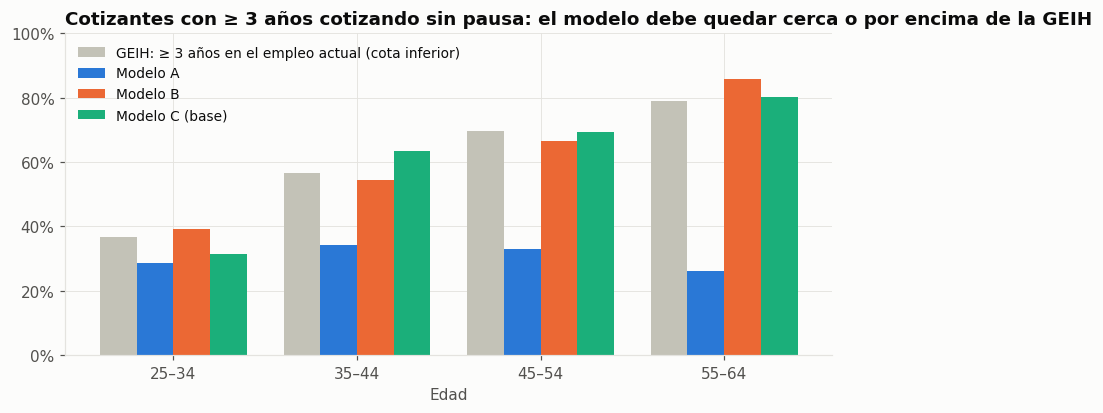

In [4]:
grupos = [(25, 34), (35, 44), (45, 54), (55, 64)]
c = geih[(geih.cotiza == 1) & geih.anio.isin(C.ANIOS_TASAS)]
obs_g = [np.average(c[c.edad.between(a, b)].antiguedad_empleo >= 36, weights=c[c.edad.between(a, b)].fex) for a, b in grupos]
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(grupos)); w = 0.2
ax.bar(x - 1.5 * w, obs_g, w, color="#c3c2b7", label="GEIH: ≥ 3 años en el empleo actual (cota inferior)")
for i, (k, m) in enumerate(modelos.items()):
    mo = C.momentos(m, pob, n_por_tipo=2_000, grupos_periodo=grupos)
    ax.bar(x + (i - 0.5) * w, [mo[f"periodo_{a}_{b}"] for a, b in grupos], w, color=SERIES[i], label=f"Modelo {k}")
ax.set_xticks(x, [f"{a}–{b}" for a, b in grupos])
ax.set_xlabel("Edad")
ax.yaxis.set_major_formatter(pct())
ax.set_ylim(0, 1)
ax.set_title("Cotizantes con ≥ 3 años cotizando sin pausa: el modelo debe quedar cerca o por encima de la GEIH")
ax.legend(loc="upper left", fontsize=9)
plt.show()

## 3. Por qué η no puede ser permanente: condicionar en la historia de un joven

El simulador condiciona en las semanas que la persona ya cotizó. Con η permanente (modelo B), el modelo "aprende" demasiado de los primeros años: quien no cotizó entre los 18 y los 25 queda marcado como alguien que casi nunca cotizará. Con η móvil hasta los 30 (modelo C), las semanas de un joven informan, pero no deciden su destino.

In [5]:
filas = []
for k, m in [("B: η permanente", mB), ("C: η móvil hasta los 30 (base)", mC)]:
    fila = {"modelo": k}
    for sem in (0, 100, 300):
        eta, est = m.condicionar(25, "Hombre", "Media", sem, 3_000, cotiza_hoy=True, seed=3)
        fut = m.simular(25, "Hombre", "Media", 37 * 12, 3_000, eta=eta, estado_inicial=est, seed=4)
        fila[f"{sem} semanas a los 25"] = np.mean(sem + C.semanas(fut)[:, -1] >= REQ_GPM["Hombre"])
    filas.append(fila)
pd.DataFrame(filas).set_index("modelo").style.format("{:.0%}").set_caption(
    "Hombre de 25 años con educación media que cotiza hoy: probabilidad de llegar a 1.150 semanas a los 62")

,0 semanas a los 25,100 semanas a los 25,300 semanas a los 25
modelo,,,
B: η permanente,1%,93%,100%
C: η móvil hasta los 30 (base),41%,47%,53%


Con η permanente, la diferencia entre tener 0 o 100 semanas a los 25 años es pasar de ~1 % a ~93 % de probabilidad de pensionarse: un resultado absurdo que el simulador habría mostrado a usuarios reales. Este problema apareció al probar el motor (paso 7) y motivó el cambio de modelo.

## 4. Validación: tasa de cotización simulada vs. observada (modelo C)

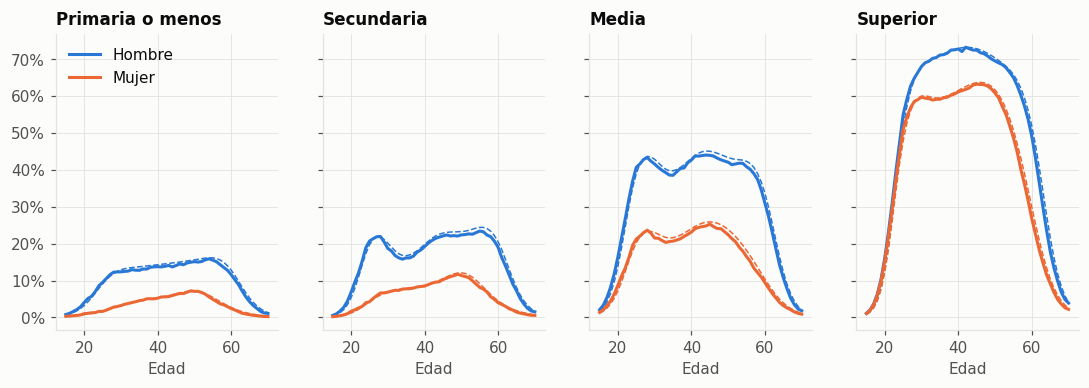

,error_abs_max_20_60
tipo,
Primaria o menos | Hombre,1.4%
Primaria o menos | Mujer,0.6%
Secundaria | Hombre,1.8%
Secundaria | Mujer,1.0%
Media | Hombre,2.7%
Media | Mujer,1.8%
Superior | Hombre,3.7%
Superior | Mujer,3.4%


In [6]:
filas = []
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), sharey=True)
for ax, e in zip(axes, NIVELES):
    for i, s in enumerate(SEXOS):
        x_ = mC.simular(C.EDAD_INICIO, s, e, len(E) * 12, 4_000, seed=11)
        anual = x_.reshape(4_000, len(E), 12).mean(axis=(0, 2))
        ax.plot(E, tasas[clave(e, s)], color=SERIES[i], lw=1, ls="--")
        ax.plot(E, anual, color=SERIES[i], label=s)
        sel = (np.array(E) >= 20) & (np.array(E) <= 60)
        filas.append({"tipo": f"{e} | {s}", "error_abs_max_20_60": np.max(np.abs(anual - tasas[clave(e, s)])[sel])})
    ax.set_title(e, fontsize=11)
    ax.set_xlabel("Edad")
axes[0].yaxis.set_major_formatter(pct())
axes[0].legend(loc="upper left")
plt.show()
pd.DataFrame(filas).set_index("tipo").style.format("{:.1%}")

Líneas continuas: tasa simulada. Líneas discontinuas: tasa objetivo de la GEIH.

## 5. ¿Cuánto cotiza cada persona? Densidad individual entre los 20 años y la edad de pensión

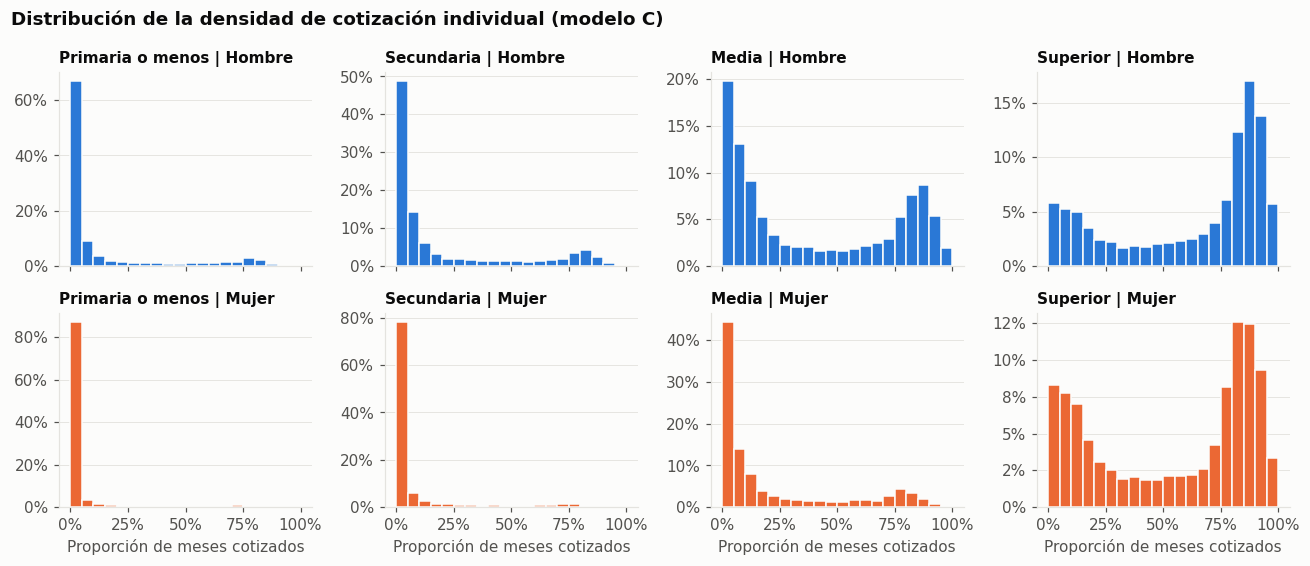

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.2), sharex=True)
for j, e in enumerate(NIVELES):
    for i, s in enumerate(SEXOS):
        d = mC.simular(20, s, e, (EDAD_PEN[s] - 20) * 12, 10_000, seed=21).mean(axis=1)
        ax = axes[i, j]
        ax.hist(d, bins=np.linspace(0, 1, 21), color=SERIES[i], edgecolor=SURFACE, linewidth=1,
                weights=np.full(len(d), 1 / len(d)))
        ax.yaxis.set_major_formatter(pct())
        ax.set_title(f"{e} | {s}", fontsize=10)
        ax.grid(axis="x", visible=False)
for ax in axes[1]:
    ax.xaxis.set_major_formatter(pct())
    ax.set_xlabel("Proporción de meses cotizados")
fig.suptitle("Distribución de la densidad de cotización individual (modelo C)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

La distribución es **bimodal**: la mayoría de las personas cotiza casi siempre o casi nunca. El tipo (educación y sexo) cambia sobre todo *cuántas* personas están en cada extremo.

## 6. Semanas acumuladas a la edad de pensión (modelo C)

In [8]:
filas = []
for e, s in C.tipos():
    w = C.semanas(mC.simular(15, s, e, (EDAD_PEN[s] - 15) * 12, 20_000, seed=1))[:, -1]
    filas.append({"educación": e, "sexo": s, "P25": np.percentile(w, 25), "mediana": np.median(w), "P75": np.percentile(w, 75),
                  "≥ req. AFP (GPM)": np.mean(w >= REQ_GPM[s]), "≥ req. Colpensiones": np.mean(w >= REQ_RPM[s])})
pd.DataFrame(filas).set_index(["educación", "sexo"]).style.format(
    {"P25": "{:,.0f}", "mediana": "{:,.0f}", "P75": "{:,.0f}", "≥ req. AFP (GPM)": "{:.1%}", "≥ req. Colpensiones": "{:.1%}"})

Requisitos para las cohortes que se pensionen después de 2036: hombres, 1.150 semanas para la garantía de pensión mínima en las AFP y 1.300 en Colpensiones; mujeres, 1.000 en ambos (sentencias C-197 de 2023 y C-054 de 2024).

## 7. La edad de consolidación se estima, y el resultado es robusto

Para cada edad de consolidación entre 25 y 40 años se recalibran $(\mu_0, \kappa, \beta, \rho_\eta)$ y se mide qué tan bien se reproducen los cuatro momentos. Luego se comparan otras variantes de la calibración.

In [9]:
g25 = geih[geih.anio == 2025].copy()
g25["educ"] = g25.nivel_educativo.astype(str).map(EDUCACION)
g25["sexo"] = g25.sexo.astype(str)

def composicion(a, b):
    w = g25[g25.edad.between(a, b)].groupby(["educ", "sexo"]).fex.sum()
    return w / w.sum()

def alcanza(m, n=8_000):
    return {(e, s): np.mean(C.semanas(m.simular(15, s, e, (EDAD_PEN[s] - 15) * 12, n, seed=1))[:, -1] >= REQ_GPM[s])
            for e, s in C.tipos()}

jov, may = composicion(25, 35), composicion(60, 70)
datos = np.array([0.82, 0.77, obj[(25, 44)], obj[(45, 64)]])

def ajuste(m):
    mo = C.momentos(m, pob)
    r = np.array([mo["cotizantes_sobre_activos"], mo["alguna_vez"], mo["periodo_25_44"], mo["periodo_45_64"]]) - datos
    return np.abs(r).max(), np.sqrt((r ** 2).mean())

base_kw = dict(objetivos_periodo=obj, objetivo_alguna_vez=0.77, x0=(0.30, 0.58, 6.19, 0.70), diff_step=0.15)
filas = []
for edad in (25, 28, 30, 32, 35, 40):
    m = mC if edad == 30 else C.calibrar(tasas, pob, edad_fija_eta=float(edad), **base_kw)
    emax, rmse = ajuste(m)
    r = alcanza(m)
    filas.append({"edad de consolidación": edad, "μ₀": m.mu, "κ": m.kappa, "β": m.beta, "ρ_η": m.rho_eta,
                  "error máximo": emax, "error cuadrático medio": rmse,
                  "alcanza semanas (25–35 años)": sum(jov[k] * r[k] for k in r)})
rejilla = pd.DataFrame(filas).set_index("edad de consolidación")
rejilla.style.format({"μ₀": "{:.3f}", "κ": "{:.2f}", "β": "{:.2f}", "ρ_η": "{:.3f}", "error máximo": "{:.3f}",
                      "error cuadrático medio": "{:.4f}", "alcanza semanas (25–35 años)": "{:.1%}"})

,μ₀,κ,β,ρ_η,error máximo,error cuadrático medio,alcanza semanas (25–35 años)
edad de consolidación,,,,,,,
25,0.193,0.75,4.21,0.619,0.006,0.0040,39.1%
28,0.252,0.68,5.30,0.678,0.003,0.0019,39.6%
30,0.300,0.58,6.19,0.700,0.002,0.0016,39.8%
32,0.308,0.40,7.04,0.727,0.012,0.0080,40.1%
35,0.314,0.07,8.44,0.738,0.018,0.0119,40.3%
40,0.210,0.18,6.82,0.847,0.043,0.0322,37.2%


Las edades de 28 a 32 años reproducen los cuatro momentos con errores menores a un punto; desde los 35 el ajuste empeora claramente. Se usa **30 años**, el centro de esa región.

In [10]:
casos = {"A: η permanente, rotación + alguna vez": mA, "B: η permanente, rotación + duración": mB, "C: η móvil hasta los 30 (base)": mC}
for nombre, cambios in [("C1: rotación 0,79", dict(objetivo_ratio=0.79)),
                        ("C2: rotación 0,86", dict(objetivo_ratio=0.86)),
                        ("C3: duración +5 puntos", dict(objetivos_periodo={g: v + 0.05 for g, v in obj.items()})),
                        ("C4: alguna vez 0,70 (10 % de registros inactivos)", dict(objetivo_alguna_vez=0.70))]:
    casos[nombre] = C.calibrar(tasas, pob, edad_fija_eta=30.0, **{**base_kw, **cambios})
filas = []
for nombre, m in casos.items():
    r = alcanza(m)
    filas.append({"calibración": nombre, "μ₀": m.mu, "κ": m.kappa, "β": m.beta, "ρ_η": m.rho_eta,
                  "composición de 25–35 años": sum(jov[k] * r[k] for k in r),
                  "composición de 60–70 años": sum(may[k] * r[k] for k in r)})
sens = pd.DataFrame(filas).set_index("calibración")
sens.style.format({"μ₀": "{:.3f}", "κ": "{:.2f}", "β": "{:.2f}", "ρ_η": "{:.3f}",
                   "composición de 25–35 años": "{:.1%}", "composición de 60–70 años": "{:.1%}"}).set_caption(
    "Proporción que alcanza las semanas de la garantía de pensión mínima")

,μ₀,κ,β,ρ_η,composición de 25–35 años,composición de 60–70 años
calibración,,,,,,
"A: η permanente, rotación + alguna vez",0.120,0.00,1.44,1.000,34.0%,16.4%
"B: η permanente, rotación + duración",0.194,0.83,4.09,1.000,37.4%,20.5%
C: η móvil hasta los 30 (base),0.300,0.58,6.19,0.700,39.8%,22.1%
"C1: rotación 0,79",0.554,0.75,7.47,0.686,40.2%,22.6%
"C2: rotación 0,86",0.095,0.36,3.54,0.738,38.4%,20.5%
C3: duración +5 puntos,0.382,0.55,8.68,0.665,40.3%,22.8%
"C4: alguna vez 0,70 (10 % de registros inactivos)",0.298,0.75,5.56,0.854,39.7%,22.1%


## 8. Condicionar en la historia de una persona de 40 años

Después de los 30, η queda fijo, así que la historia sí es muy informativa.

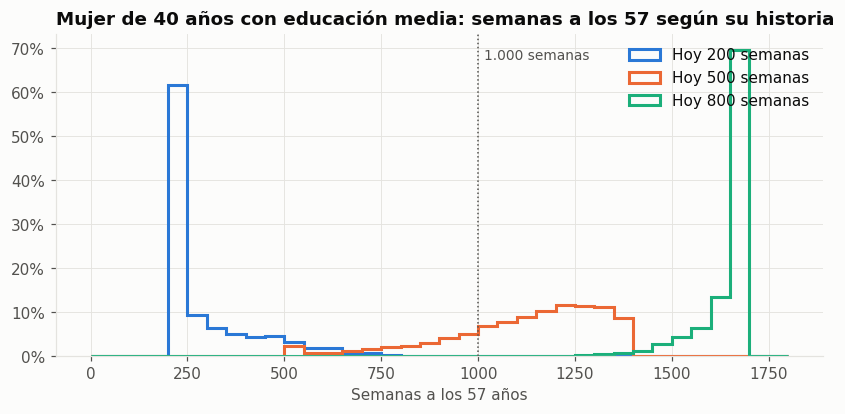

,cotiza hoy,mediana a los 57,P(≥ 1.000)
semanas a los 40,,,
200,10%,209,0%
500,76%,"1,169",77%
800,98%,"1,674",100%


In [11]:
fig, ax = plt.subplots(figsize=(9, 3.8))
filas = []
for i, sem in enumerate([200, 500, 800]):
    eta, est = mC.condicionar(40, "Mujer", "Media", sem, 4_000, seed=31)
    fut = mC.simular(40, "Mujer", "Media", (57 - 40) * 12, 4_000, eta=eta, estado_inicial=est, seed=32)
    total = sem + C.semanas(fut)[:, -1]
    ax.hist(total, bins=np.arange(0, 1801, 50), histtype="step", lw=2, color=SERIES[i],
            weights=np.full(len(total), 1 / len(total)), label=f"Hoy {sem} semanas")
    filas.append({"semanas a los 40": sem, "cotiza hoy": est.mean(), "mediana a los 57": np.median(total),
                  "P(≥ 1.000)": np.mean(total >= 1000)})
ax.axvline(1000, color=INK2, lw=1, ls=":")
ax.annotate("1.000 semanas", (1000, ax.get_ylim()[1] * 0.92), xytext=(4, 0), textcoords="offset points", color=INK2, fontsize=9)
ax.yaxis.set_major_formatter(pct())
ax.set_xlabel("Semanas a los 57 años")
ax.set_title("Mujer de 40 años con educación media: semanas a los 57 según su historia")
ax.legend(loc="upper right")
plt.show()
pd.DataFrame(filas).set_index("semanas a los 40").style.format({"cotiza hoy": "{:.0%}", "mediana a los 57": "{:,.0f}", "P(≥ 1.000)": "{:.0%}"})

## Hallazgos

1. **La densidad de cotización es bimodal.** La mayoría cotiza casi siempre o casi nunca. Lo que separa a los tipos es cuántas personas están en cada extremo, no una densidad "promedio" que todos comparten. Con la tasa promedio nadie llegaría a las semanas (notebook 01); con la heterogeneidad, una fracción importante sí llega.
2. **La validación obligó a cambiar el modelo dos veces:**
   - Con rotación constante, los periodos de cotización de los mayores quedaban por debajo de su antigüedad en el empleo. Se agregó la caída de la rotación con la edad (κ).
   - Con η permanente, las semanas de un joven decidían su destino: a los 25 años, 0 o 100 semanas eran 1 % o 93 % de probabilidad de pensionarse. Esto apareció al probar el motor (paso 7). Con η móvil en la juventud, la probabilidad queda entre el 41 % y el 53 %, y además el modelo reproduce "alguna vez cotizó" (77 %), que antes no lograba (61 %).
3. **La edad a la que se consolida la situación laboral se estima con los datos:** 30 años (las edades de 28 a 32 ajustan los cuatro momentos con errores menores a un punto; desde los 35 el ajuste empeora). Con η móvil a todas las edades no es posible reproducir los periodos largos de los mayores.
4. **El resultado central es robusto.** La proporción que alcanza las semanas de la garantía de pensión mínima (composición de los jóvenes) es 39,8 %. Va de 39,1 % a 40,3 % con edades de consolidación de 25 a 35, y de 38,4 % a 40,3 % con las demás variantes de la calibración. Los modelos con η permanente dan 34–37 %.
5. **Brechas enormes por educación y sexo.** La proporción que alcanza las semanas va del 4 % (mujeres con primaria o menos) al 67 % (hombres con educación superior). Las mujeres cotizan menos meses, aunque la reducción de semanas a 1.000 compensa parte de la brecha.
6. **La historia pesa más con la edad.** A los 25 años, tener 0 o 300 semanas cambia la probabilidad de pensionarse de 41 % a 53 %. A los 40, una mujer con educación media pasa de 0 % (200 semanas) a 77 % (500) y 100 % (800).
7. **Validación:** la cadena reproduce las tasas por edad de la GEIH (error máximo de ~4 puntos) y los cuatro momentos de calibración con un error máximo de 0,2 puntos. Con la composición educativa de quienes hoy tienen 60–70 años da 22 %, del mismo orden que las cifras públicas de cobertura (18–30 %).

**Limitaciones:**
- Entre los 25 y los 34 años el modelo genera más rotación de la que sugiere la antigüedad observada (ver la figura de periodos). Puede subestimar algo la cotización de los jóvenes.
- Las tasas por edad son de corte transversal (2023–2025): no hay tendencia de formalización.
- η no está correlacionado con el salario del paso 4.
- La rotación administrativa tiene definiciones ambiguas: la fila de las AFP del dataset parece tener las columnas invertidas.